# Housing Price Prediction — Simple EDA and Multiple Linear Regression

**Goal:** Predict house `price` using the other columns in `Housing.csv`.

This is **Multiple Linear Regression**, not Logistic Regression. Linear Regression is used because `price` is a continuous number. Logistic Regression is used for classification targets such as Yes/No.

Run the notebook from top to bottom. Keep `Housing.csv` in the same folder as this notebook.

## Step 1: Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## Step 2: Load the dataset

In [2]:
df = pd.read_csv("Housing.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## Step 3: Understand the data

In [3]:
# Number of rows and columns
df.shape

(545, 13)

In [4]:
# Column names
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [5]:
# Data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
# Basic statistical summary
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [7]:
# Missing values in each column
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [8]:
# Number of duplicate rows
df.duplicated().sum()

0

## Step 4: Simple data cleaning

In [9]:
# Remove duplicate rows, if any
df = df.drop_duplicates()

# Check the dataset again
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Dataset shape: (545, 13)
Missing values: 0


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## Step 5: Exploratory Data Analysis (EDA)

### 5.1 Check the house price distribution

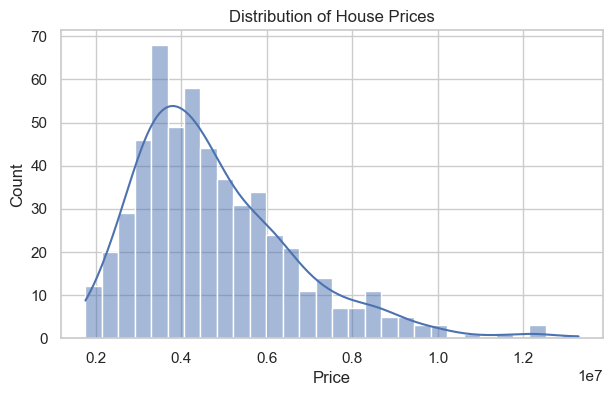

In [10]:
plt.figure(figsize=(7, 4))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.show()

### 5.2 Area vs price

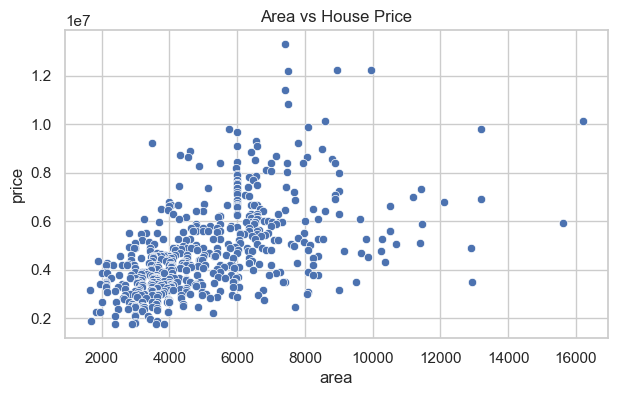

In [11]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="area", y="price")
plt.title("Area vs House Price")
plt.show()

### 5.3 Bedrooms vs price


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



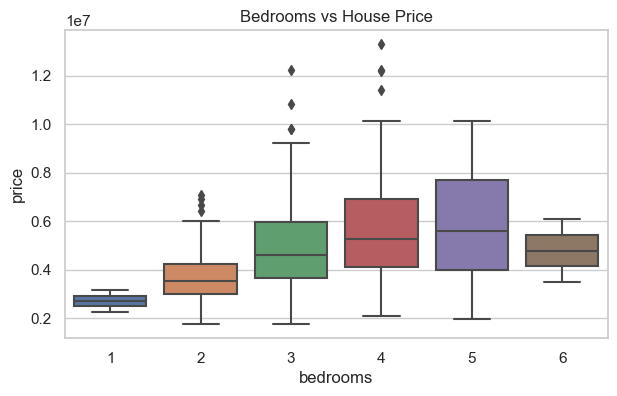

In [12]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="bedrooms", y="price")
plt.title("Bedrooms vs House Price")
plt.show()

### 5.4 Furnishing status vs price

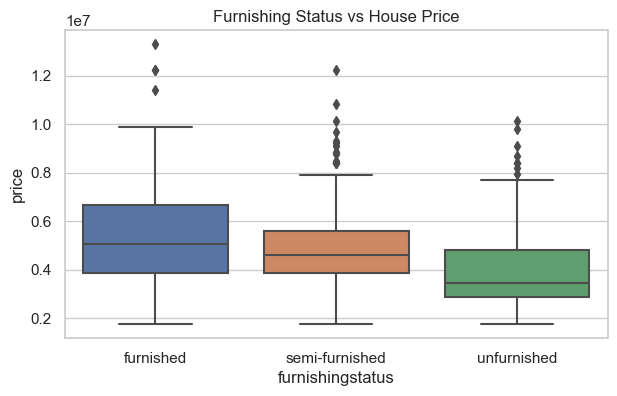

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="furnishingstatus", y="price")
plt.title("Furnishing Status vs House Price")
plt.show()

### 5.5 Correlation between numerical columns

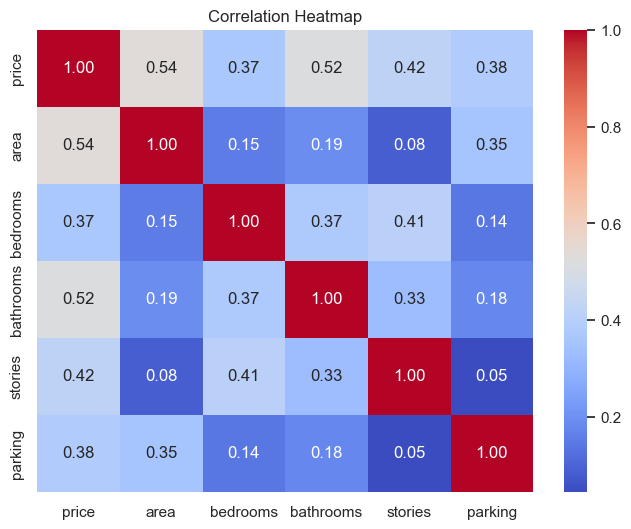

In [14]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Step 6: Separate features (X) and target (y)

- **X:** all input columns used to predict price.
- **y:** `price`, the value we want to predict.

The text columns (for example, `mainroad` and `furnishingstatus`) must be converted into numbers. We use `pd.get_dummies()` for this.

In [15]:
X = df.drop("price", axis=1)
y = df["price"]

# Convert categorical/text columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Input features:", X.columns.tolist())
print("Target:", y.name)
X.head()

Input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Target: price


,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,7420,4,1,2,2,1,1,1,0,1,0,0,0


## Step 7: Split the data into training and testing sets

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 436
Testing rows: 109


## Step 8: Create and train the Multiple Linear Regression model

In [17]:
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


## Step 9: Predict house prices

In [18]:
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(0)
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5164654.0
1,6650000,7224722.0
2,3710000,3109863.0
3,6440000,4612075.0
4,2800000,3294646.0
5,4900000,3532275.0
6,5250000,5611775.0
7,4543000,6368146.0
8,2450000,2722857.0
9,3353000,2629406.0


## Step 10: Evaluate the model

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

MAE: 970043.4
MSE: 1754318687330.66
RMSE: 1324506.96
R2 Score: 0.653


### What do these evaluation values mean?

- **MAE:** Average absolute difference between actual and predicted prices. Lower is better.
- **MSE:** Average squared prediction error. Lower is better.
- **RMSE:** Error in the same unit as house price. Lower is better.
- **R² Score:** How much variation in house prices the model explains. Closer to 1 is generally better.

## Step 11: Actual price vs predicted price

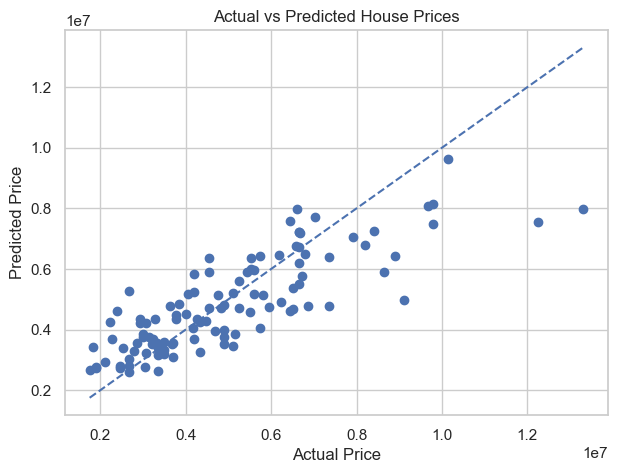

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

# A diagonal line represents perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.show()

## Step 12: Check feature coefficients

In [21]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    by="Coefficient", ascending=False
)

,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04
